# Introduction

## CNN from scratch for classifying MNIST digits.

In this Lab session we will learn how to train a CNN from scratch for classifying MNIST digits.

NOTE: All text cells starting with a number indicate that you have to write code or write a response. However, read all the cells to understand the full pipeline.

IMPORTANT: The goal is for you to learn how CNNs are implemented and trained with Pytorch. Using AI to write code for you harms this learning process, so it is strictly forbidden to use AI to write code. Feel free to use AI to _learn_ about Pytorch, CNNs, etc., but you are highly encouraged to read Pytorch's very good documentation, too. Concepts you learn in this assignment will be relevant for the exam.

In [ ]:
# import necessary libraries
import torch 
import torchvision 
from torchvision import transforms as T
import torch.nn.functional as F
import torch.nn as nn

### 1. Define LeNet

![network architecture](https://www.researchgate.net/profile/Lucijano-Berus/publication/329891470/figure/fig1/AS:707347647307776@1545656229128/Architecture-of-LeNet-5-a-Convolutional-Neural-Network-for-digits-digits-recognition-An.ppm)

Here we are going to define our first CNN which is **LeNet** in this case. This architecture has been introduced and is detailed in [this article](http://vision.stanford.edu/cs598_spring07/papers/Lecun98.pdf). To construct a LeNet we will be using two convolutional layers followed by three fully-connected layers as indicated in the figure. The convolutional layers can be defined using `torch.nn.Conv2d` module of `torch.nn` package. Details can be found [here](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html). Moreover, we will use a pooling operation to reduce the size of convolutional feature maps. For this case we are going to use `torch.nn.functional.max_pool2d`. Details about maxpooling can be found [here](https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.max_pool2d.html)

we will use a Rectified Linear Units (ReLU) as activation function with the help of `torch.nn.functional.relu`, replacing `torch.nn.Sigmoid`. Details about ReLU can be found [here](https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.relu.html).

Note: The figure shows 32x32 input size while your data will be slightly differnt. You can either pad the input or adjust the network architecture slightly (as little as possible).

In [ ]:
class LeNet(torch.nn.Module):
  def __init__(self, cifar10=False, dropout = 0):
    super(LeNet, self).__init__()

    # input channel = 1, output channels = 6, kernel size = 5*5
    # input image size = (28, 28), padding = 2, image output size = (28,28)
    if not cifar10:
      self.cnn1 = nn.Conv2d(1,6,5,padding=2)
    else : 
      self.cnn1 = nn.Conv2d(3,6,5)

    # input channel = 6, output channels = 16, kernel size = 5
    # input image size = (14,14), output image size = (10,10)
    self.cnn2 = nn.Conv2d(6,16,5)

    # input dim = 400 ( H x W x C), output dim = 120
    self.fc1 = nn.Linear(400,120)

    # input dim = 120, output dim = 84
    self.fc2 = nn.Linear(120,84)

    # input dim = 84 output dim = 10
    self.fc3 = nn.Linear(84,10)
    self.dropout = nn.Dropout(dropout)


  def forward(self, x):

    x = F.relu(self.cnn1(x))
    # Max Pooling with kernel size = 2
    # output size = (14, 14)
    x = F.max_pool2d(x,kernel_size=2)
    x = F.relu(self.cnn2(x))
    # Max Pooling with kernel size = 2
    # output size = (5, 5)
    x = F.max_pool2d(x,kernel_size=2)
    # flatten the feature maps into a long vector
    x = x.view(x.shape[0], -1)
    x = F.relu(self.fc1(x))
    x = self.dropout(x)
    x = F.relu(self.fc2(x))
    x = self.dropout(x)
    x = self.fc3(x) #no relu for the last one
    return x

### 2. Define cost function
Hint: Make sure to read the documentation of the loss function you use to validate that your network output matches what the loss expects as input.

In [25]:
def get_cost_function():
  cost_function = nn.CrossEntropyLoss()
  return cost_function

### 3. Define the optimizer

We will use SGD with learning rate-lr, weight_decay=wd and  momentum=momentum

In [26]:
def get_optimizer(net, lr, wd, momentum):
  optimizer =  torch.optim.SGD(net.parameters(), lr=lr,momentum=momentum,weight_decay=wd)
  return optimizer

### Train and test functions

In [ ]:
def test(net, data_loader, cost_function, device='mps'):
  samples = 0.
  cumulative_loss = 0.
  cumulative_accuracy = 0.

  net.eval() # Strictly needed if network contains layers which has different behaviours between train and test
  with torch.no_grad():
    for batch_idx, (inputs, targets) in enumerate(data_loader):
      # Load data into GPU
      inputs = inputs.to(device)
      targets = targets.to(device)

      # Forward pass
      outputs = net(inputs)

      # Apply the loss
      loss = cost_function(outputs, targets)

      # Better print something
      samples+=inputs.shape[0]
      cumulative_loss += loss.item()*inputs.shape[0] # Note: the .item() is needed to extract scalars from tensors
      _, predicted = outputs.max(1) # it is the prediction the output is a soft classification
      cumulative_accuracy += predicted.eq(targets).sum().item()

  return cumulative_loss/samples, cumulative_accuracy/samples*100


def train(net,data_loader,optimizer,cost_function, device='mps'):
  samples = 0.
  cumulative_loss = 0.
  cumulative_accuracy = 0.


  net.train() # Strictly needed if network contains layers which has different behaviours between train and test
  for batch_idx, (inputs, targets) in enumerate(data_loader):
    # Load data into GPU
    inputs = inputs.to(device)
    targets = targets.to(device)

    # Forward pass
    outputs = net(inputs)

    # Apply the loss
    loss = cost_function(outputs,targets)

    # Reset the optimizer
    optimizer.zero_grad()

    # Backward pass
    loss.backward()

    # Update parameters
    optimizer.step()

    # Better print something, no?
    samples+=inputs.shape[0]
    cumulative_loss += loss.item()* inputs.shape[0]
    _, predicted = outputs.max(1)
    cumulative_accuracy += predicted.eq(targets).sum().item()

  return cumulative_loss/samples, cumulative_accuracy/samples*100

### Define the function that fetches a data loader that is then used during iterative training.

We will learn a new thing in this function as how to Normalize the inputs given to the network.

***Why Normalization is needed***?

To have nice and stable training of the network it is recommended to normalize the network inputs between \[-1, 1\].

***How it can be done***?

This can be simply done using `torchvision.transforms.Normalize()` transform. Details can be found [here](https://docs.pytorch.org/vision/stable/generated/torchvision.transforms.Normalize.html).

In [ ]:
def get_data(batch_size, test_batch_size=256, cif= False, data_augmentation= False):

  
  
  # Prepare data transformations and then combine them sequentially
  transform = list()
  transform.append(T.ToTensor())                            # converts Numpy to Pytorch Tensor
  transform.append(T.Normalize(mean=[0.5], std=[0.5]))      # Normalizes the Tensors between [-1, 1]
  transform = T.Compose(transform)                          # Composes the above transformations into one.

  # Load data
  if not cif: 
    full_training_data = torchvision.datasets.MNIST('./data', train=True, transform=transform, download=True)
    test_data = torchvision.datasets.MNIST('./data', train=False, transform=transform, download=True)
  else : 
    full_training_data = torchvision.datasets.CIFAR10('./data', train=True, transform=transform, download=True)
    test_data = torchvision.datasets.CIFAR10('./data', train=False, transform=transform, download=True)


  # Create train and validation splits
  num_samples = len(full_training_data)
  training_samples = int(num_samples*0.5+1)
  validation_samples = num_samples - training_samples

  training_data, validation_data = torch.utils.data.random_split(full_training_data, [training_samples, validation_samples])

  # Initialize dataloaders
  train_loader = torch.utils.data.DataLoader(training_data, batch_size, shuffle=True)
  val_loader = torch.utils.data.DataLoader(validation_data, test_batch_size, shuffle=False)
  test_loader = torch.utils.data.DataLoader(test_data, test_batch_size, shuffle=False)

  return train_loader, val_loader, test_loader

### 4. Initializing model and wrapping everything up

Finally, we need a main function which initializes everything + the needed hyperparameters and loops over multiple epochs (printing the results).

In [ ]:
'''
Input arguments
  batch_size: Size of a mini-batch
  device: GPU where you want to train your network
  weight_decay: Weight decay co-efficient for regularization of weights
  momentum: Momentum for SGD optimizer
  epochs: Number of epochs for training the network
'''

def main(batch_size=128,
         device='mps',
         learning_rate=0.01,
         weight_decay=0.000001,
         momentum=0.9,
         epochs=50,
         sequential = False,
         early_stopping = 0,
         cif= False,
         dropout = 0,
         Res_net = False,
         ):


  train_loader, val_loader, test_loader = get_data(batch_size, cif = cif)



  if sequential:
    net = model_seq.to(device)
  elif Res_net :
    # Load pre-trained ResNet18 model
    net = torchvision.models.resnet18(pretrained=True)
    # Replace the last fully connected layer
    # The number of input features to the last layer of ResNet18 is 512
    num_ftrs = net.fc.in_features # last layer see doc
    net.fc = nn.Linear(num_ftrs, 10) # CIFAR10 has 10 classes
    net = net.to(device)
  else:
    net = LeNet(cifar10 = cif, dropout = dropout).to(device)



  optimizer = get_optimizer(net, learning_rate, weight_decay, momentum)

  cost_function = get_cost_function()

  print('Before training:')
  train_loss, train_accuracy = test(net, train_loader, cost_function)
  val_loss, val_accuracy = test(net, val_loader, cost_function)
  test_loss, test_accuracy = test(net, test_loader, cost_function)

  print('\t Training loss {:.5f}, Training accuracy {:.2f}'.format(train_loss, train_accuracy))
  print('\t Validation loss {:.5f}, Validation accuracy {:.2f}'.format(val_loss, val_accuracy))
  print('\t Test loss {:.5f}, Test accuracy {:.2f}'.format(test_loss, test_accuracy))
  print('-----------------------------------------------------')
  #early-stopping
  count = 0
  min_loss = float("inf")
  min_delta = 1e-5
  for e in range(epochs):
    train_loss, train_accuracy = train(net, train_loader, optimizer, cost_function)
    val_loss, val_accuracy = test(net, val_loader, cost_function)
    print('Epoch: {:d}'.format(e+1))
    print('\t Training loss {:.5f}, Training accuracy {:.2f}'.format(train_loss, train_accuracy))
    print('\t Validation loss {:.5f}, Validation accuracy {:.2f}'.format(val_loss, val_accuracy))
    print('-----------------------------------------------------')
    if early_stopping :#true si dif de zéro
      if val_loss > min_loss - min_delta:
        count += 1
        if count == early_stopping :
          print(f"early stop at {e} epochs") 
          break
      else:
        count = 0
        min_loss = val_loss


  print('After training:')
  train_loss, train_accuracy = test(net, train_loader, cost_function)
  val_loss, val_accuracy = test(net, val_loader, cost_function)
  test_loss, test_accuracy = test(net, test_loader, cost_function)

  print('\t Training loss {:.5f}, Training accuracy {:.2f}'.format(train_loss, train_accuracy))
  print('\t Validation loss {:.5f}, Validation accuracy {:.2f}'.format(val_loss, val_accuracy))
  print('\t Test loss {:.5f}, Test accuracy {:.2f}'.format(test_loss, test_accuracy))
  print('-----------------------------------------------------')
  return net, test_loader

Lets train!

In [13]:
net, test_loader = main()

Before training:
	 Training loss 0.01803, Training accuracy 13.20
	 Validation loss 0.00906, Validation accuracy 13.23
	 Test loss 0.00922, Test accuracy 12.39
-----------------------------------------------------
Epoch: 1
	 Training loss 0.00841, Training accuracy 65.28
	 Validation loss 0.00075, Validation accuracy 93.94
-----------------------------------------------------
Epoch: 2
	 Training loss 0.00111, Training accuracy 95.56
	 Validation loss 0.00039, Validation accuracy 96.79
-----------------------------------------------------
Epoch: 3
	 Training loss 0.00074, Training accuracy 97.08
	 Validation loss 0.00038, Validation accuracy 96.95
-----------------------------------------------------
Epoch: 4
	 Training loss 0.00056, Training accuracy 97.71
	 Validation loss 0.00028, Validation accuracy 97.86
-----------------------------------------------------
Epoch: 5
	 Training loss 0.00045, Training accuracy 98.23
	 Validation loss 0.00024, Validation accuracy 98.13
---------------

#### Optional: Plot the training and validation curves.



### 5. Plot a confusion matrix to check which MNIST digit is most frequently confused with which other digit. Can you explain why?



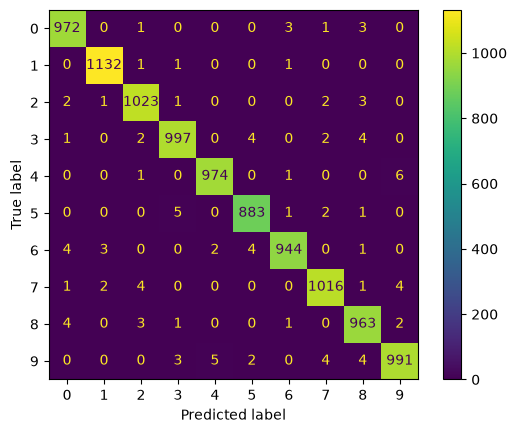

In [14]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
def confusion_matrix(net,test_loader, device = "mps"):
    net.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for x, y in test_loader:
            outputs = net(x.to(device))
            y_true.extend(y.tolist())
            y_pred.extend(outputs.argmax(dim=1).cpu().tolist())

    ConfusionMatrixDisplay.from_predictions(y_true, y_pred)
    plt.show()
    return None

confusion_matrix(net, test_loader)

### For the remaining tasks try to integrate the changes in the code above while avoiding duplicate code as much as possible. For every task, introduce flags (i.e., function arguments) to the main() function to enable the new functionality of the task. It should always be possible to run the original implementation above. Finally, call the main function with the correct flags for each task in the cells below.

### 6. The LeNet5 architecture can also be implemented using the sequential API ([see documentation](https://pytorch.org/docs/stable/generated/torch.nn.Sequential.html)). Reimplement it with this API and run training + evaluation once to verify it works.

Before training:
	 Training loss 0.01807, Training accuracy 8.49
	 Validation loss 0.00907, Validation accuracy 9.01
	 Test loss 0.00923, Test accuracy 8.52
-----------------------------------------------------
Epoch: 1
	 Training loss 0.01060, Training accuracy 53.10
	 Validation loss 0.00099, Validation accuracy 92.28
-----------------------------------------------------
Epoch: 2
	 Training loss 0.00118, Training accuracy 95.44
	 Validation loss 0.00045, Validation accuracy 96.54
-----------------------------------------------------
Epoch: 3
	 Training loss 0.00071, Training accuracy 97.06
	 Validation loss 0.00038, Validation accuracy 97.21
-----------------------------------------------------
Epoch: 4
	 Training loss 0.00052, Training accuracy 97.94
	 Validation loss 0.00028, Validation accuracy 97.75
-----------------------------------------------------
Epoch: 5
	 Training loss 0.00042, Training accuracy 98.28
	 Validation loss 0.00031, Validation accuracy 97.50
------------------

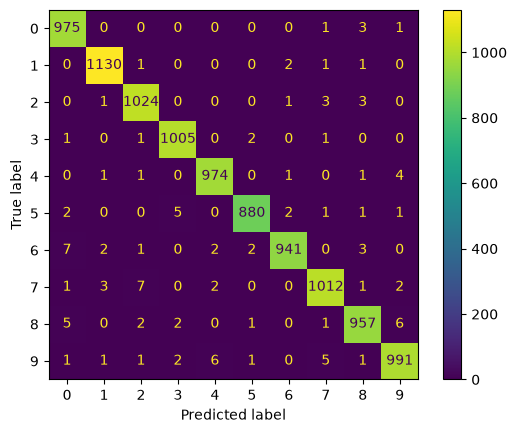

In [15]:
model_seq = nn.Sequential(
    nn.Conv2d(1,6,5,padding=2),nn.ReLU(),nn.MaxPool2d(2),
    nn.Conv2d(6,16,5), nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(400,120), nn.ReLU(),
    nn.Linear(120,84), nn.ReLU(),
    nn.Linear(84,10),
)

net, test_loader = main(sequential=True)
confusion_matrix(net, test_loader)


### 7. Implement adaptive early stopping: if the validation loss did not decrease for K consecutive epochs, stop training.

Before training:
	 Training loss 0.01804, Training accuracy 11.76
	 Validation loss 0.00906, Validation accuracy 11.72
	 Test loss 0.00921, Test accuracy 11.90
-----------------------------------------------------
Epoch: 1
	 Training loss 0.00928, Training accuracy 61.89
	 Validation loss 0.00077, Validation accuracy 93.98
-----------------------------------------------------
Epoch: 2
	 Training loss 0.00111, Training accuracy 95.66
	 Validation loss 0.00048, Validation accuracy 96.27
-----------------------------------------------------
Epoch: 3
	 Training loss 0.00074, Training accuracy 97.07
	 Validation loss 0.00036, Validation accuracy 97.14
-----------------------------------------------------
Epoch: 4
	 Training loss 0.00057, Training accuracy 97.72
	 Validation loss 0.00029, Validation accuracy 97.64
-----------------------------------------------------
Epoch: 5
	 Training loss 0.00047, Training accuracy 98.13
	 Validation loss 0.00029, Validation accuracy 97.64
---------------

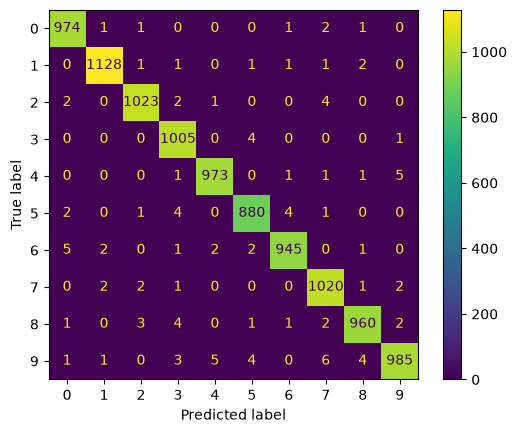

In [21]:
model_seq = nn.Sequential(
    nn.Conv2d(1,6,5,padding=2),nn.ReLU(),nn.MaxPool2d(2),
    nn.Conv2d(6,16,5), nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(400,120), nn.ReLU(),
    nn.Linear(120,84), nn.ReLU(),
    nn.Linear(84,10),
)
#initialise the weight of the model 

net, test_loader = main(sequential=True, early_stopping=1)
confusion_matrix(net, test_loader)

### 8. Change the dataset in order to train and evaluate the LeNet5 network on [CIFAR10](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.CIFAR10.html).

In [ ]:
#modification directly in the function get the data and directer on the class also only for the first layer 
main(early_stopping=1, cif = True)


### 9. Try to improve the performance on CIFAR10 with both:
   *   data-augmentation
   *   dropout

In [ ]:
def get_data(batch_size, test_batch_size=256, cif=False):

    if cif:
        train_transform = T.Compose([
            T.RandomCrop(32, padding=4),
            T.RandomHorizontalFlip(p=0.5),
            T.ToTensor(),
            T.Normalize([0.5]*3, [0.5]*3)
        ])

        test_transform = T.Compose([
            T.ToTensor(),
            T.Normalize([0.5]*3, [0.5]*3)
        ])

        full_training_data = torchvision.datasets.CIFAR10('./data', train=True, transform=train_transform, download=True)

        validation_dataset = torchvision.datasets.CIFAR10('./data', train=True, transform=test_transform, download=True)

        test_data = torchvision.datasets.CIFAR10('./data', train=False, transform=test_transform, download=True)

    else:
        transform = T.Compose([
            T.ToTensor(),
            T.Normalize([0.5], [0.5])
        ])

        full_training_data = torchvision.datasets.MNIST('./data', train=True, transform=transform, download=True)
        validation_dataset = full_training_data
        test_data = torchvision.datasets.MNIST( './data', train=False, transform=transform, download=True)

    # Train / Validation split
    num_samples = len(full_training_data)
    training_samples = int(num_samples * 0.5)
    indices = torch.randperm(num_samples).tolist()
    training_data = torch.utils.data.Subset(full_training_data, indices[:training_samples])
    validation_data = torch.utils.data.Subset(validation_dataset, indices[training_samples:])
    # DataLoaders
    train_loader = torch.utils.data.DataLoader(training_data, batch_size=batch_size, shuffle=True)
    val_loader = torch.utils.data.DataLoader(validation_data, batch_size=test_batch_size, shuffle=False)
    test_loader = torch.utils.data.DataLoader(test_data, batch_size=test_batch_size, shuffle=False)

    return train_loader, val_loader, test_loader

main(early_stopping=2, cif = True, dropout = 0.2)


### 10. Use the ResNet18 class from Pytorch to train and evaluate a ResNet on CIFAR10 (make sure it works, but if it takes too long, you don't have to train until convergence).

In [ ]:

main(early_stopping=2, cif = True, Res_net=True)